# Chapter 6 - Hyperparameter Optimisation

This notebook tunes the three classifiers from Chapter 5 on the frozen 70/15/15 split. Each model receives 60 candidates. Candidate #0 is the exact Chapter 5 configuration and candidates #1 to #59 are seeded random draws. Every candidate is fitted on the training split and scored once on the validation split. The test split is not read.

Candidates are ranked by validation AUC-ROC, then PR-AUC, then F1 at the 0.5 cut-off, then the lower candidate index. Threshold selection is handled after this chapter. The final section tests the rank-weighted extension and reports the result.


In [1]:
# 0. Setup: imports, portable paths, fixed seed
from pathlib import Path
import json
import math
import random
import sys
import time
from datetime import datetime, timezone

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from xgboost import XGBClassifier

# Paths are relative to this notebook (bank/notebook/), so nothing is machine-specific.
BASE_DIR = Path("..")
DATA_DIR = BASE_DIR / "data_processed"
MODEL_DIR = DATA_DIR / "model_results"
PRED_DIR = DATA_DIR / "predictions"
OUT_DIR = BASE_DIR / "outputs" / "chapter_06"
for folder in (MODEL_DIR, PRED_DIR, OUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

TARGET = "default.payment.next.month"
ID_COL = "ID"
SEED = 42
N_CANDIDATES = 60
N_RANDOM = N_CANDIDATES - 1

spec = json.loads((DATA_DIR / "preprocessing_spec.json").read_text(encoding="utf-8"))
FEATURES = spec["feature_sets"][spec["selected_set"]]

random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 140)

if sklearn.__version__ != "1.9.1":
    raise RuntimeError(f"This notebook requires scikit-learn 1.9.1, found {sklearn.__version__}")

def to_python(value):
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    return value

def clean_param(name, value):
    value = to_python(value)
    if value is None:
        return None
    if isinstance(value, float) and math.isnan(value):
        return None
    if name in {"n_estimators", "max_depth", "min_samples_split",
                "min_samples_leaf", "min_child_weight"}:
        if isinstance(value, float) and value.is_integer():
            return int(value)
    return value

print(f"Features: {len(FEATURES)}")
print(f"Candidates per model: {N_CANDIDATES} (baseline #0 + {N_RANDOM} random draws)")
print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__} | xgboost {xgboost.__version__}")

Features: 23
Candidates per model: 60 (baseline #0 + 59 random draws)
Python 3.11.9 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.4.6 | xgboost 3.2.0


In [2]:
# 1. Load the frozen training and validation splits. The test file is not read.
train = pd.read_csv(DATA_DIR / "train.csv")
val = pd.read_csv(DATA_DIR / "val.csv")

assert len(train) == 20975, len(train)
assert len(val) == 4495, len(val)
assert set(FEATURES).issubset(train.columns)
assert set(FEATURES).issubset(val.columns)
assert train[TARGET].isin([0, 1]).all()
assert val[TARGET].isin([0, 1]).all()

print(f"Train rows            : {len(train):,}")
print(f"Validation rows       : {len(val):,}")
print(f"Model columns         : {len(FEATURES)}")
print(f"Train default rate    : {train[TARGET].mean():.4f}")
print(f"Validation default rate: {val[TARGET].mean():.4f}")

Train rows            : 20,975
Validation rows       : 4,495
Model columns         : 23
Train default rate    : 0.2213
Validation default rate: 0.2211


In [3]:
# 2. One evaluation function, identical to Chapter 5.
def evaluate(model, frame):
    pred = model.predict(frame[FEATURES])
    proba = model.predict_proba(frame[FEATURES])[:, 1]
    y = frame[TARGET]
    metrics = {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred),
        "Recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "AUC": roc_auc_score(y, proba),
        "PR-AUC": average_precision_score(y, proba),
    }
    return metrics, proba

In [4]:
# 3. Baseline configurations. Only the declared search parameters are varied later.
POS_WEIGHT = float((train[TARGET] == 0).sum() / (train[TARGET] == 1).sum())

FIXED = {
    "A": {
        "solver": "lbfgs",
        "max_iter": 1000,
        "fit_intercept": True,
        "tol": 1e-4,
        "random_state": SEED,
    },
    "B": {
        "bootstrap": True,
        "criterion": "gini",
        "oob_score": False,
        "warm_start": False,
        "max_samples": None,
        "max_leaf_nodes": None,
        "min_weight_fraction_leaf": 0.0,
        "min_impurity_decrease": 0.0,
        "ccp_alpha": 0.0,
        "n_jobs": -1,
        "random_state": SEED,
    },
    "C": {
        "booster": "gbtree",
        "objective": "binary:logistic",
        "tree_method": "hist",
        "eval_metric": "auc",
        "n_jobs": -1,
        "random_state": SEED,
        "reg_alpha": 0,
        "colsample_bylevel": 1,
        "colsample_bynode": 1,
        "max_delta_step": 0,
    },
}

BASELINE = {
    "A": {"C": 1.0, "class_weight": "balanced"},
    "B": {"n_estimators": 500, "max_depth": None, "min_samples_split": 2,
          "min_samples_leaf": 1, "max_features": "sqrt",
          "class_weight": "balanced_subsample"},
    "C": {"n_estimators": 400, "learning_rate": 0.05, "max_depth": 4,
          "subsample": 0.8, "colsample_bytree": 0.8, "min_child_weight": 1,
          "gamma": 0.0, "reg_lambda": 1.0, "scale_pos_weight": POS_WEIGHT},
}

print(f"scale_pos_weight = {POS_WEIGHT:.6f}")

scale_pos_weight = 3.519500


In [5]:
# 4. Search spaces. Every baseline value is included in its space.
SPACES = {
    "A": {
        "C": {"kind": "log_uniform", "low": 1e-3, "high": 30.0},
        "class_weight": ["balanced", None],
    },
    "B": {
        "n_estimators": [300, 500, 800],
        "max_depth": [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5],
        "class_weight": ["balanced", "balanced_subsample", None],
    },
    "C": {
        "n_estimators": [200, 300, 400, 600, 800],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "max_depth": [2, 3, 4, 5, 6],
        "subsample": [0.6, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "min_child_weight": [1, 5, 10],
        "gamma": [0, 0.1, 0.3],
        "reg_lambda": [1, 5, 10],
        "scale_pos_weight": [1, POS_WEIGHT, 5, 10],
    },
}

In [6]:
# 5. Candidate sampler: baseline #0 plus 59 seeded random draws.
def candidate_key(params, space):
    key = []
    for name in space:
        value = params[name]
        if isinstance(value, float):
            value = round(value, 12)
        key.append(value)
    return tuple(key)

def sample_candidates(model_name, n_random=N_RANDOM):
    rng = random.Random(SEED + {"A": 1, "B": 2, "C": 3}[model_name])
    space = SPACES[model_name]
    candidates = [dict(BASELINE[model_name])]
    seen = {candidate_key(candidates[0], space)}
    while len(candidates) < 1 + n_random:
        candidate = {}
        for name, values in space.items():
            if isinstance(values, dict):
                low, high = values["low"], values["high"]
                candidate[name] = 10 ** rng.uniform(math.log10(low), math.log10(high))
            else:
                candidate[name] = rng.choice(values)
        key = candidate_key(candidate, space)
        if key in seen:
            continue
        seen.add(key)
        candidates.append(candidate)
    return candidates

CANDIDATES = {name: sample_candidates(name) for name in ("A", "B", "C")}
for name, candidates in CANDIDATES.items():
    unique = len({candidate_key(c, SPACES[name]) for c in candidates})
    print(f"Model {name}: {len(candidates)} candidates, {unique} unique")
    display(pd.DataFrame(candidates).head(3))

Model A: 60 candidates, 60 unique


,C,class_weight
0,1.000000,balanced
1,0.001488,balanced
2,19.741428,NaN


Model B: 60 candidates, 60 unique


,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
0,500,NaN,2,1,sqrt,balanced_subsample
1,500,NaN,2,2,sqrt,balanced_subsample
2,300,10.0,2,4,sqrt,balanced


Model C: 60 candidates, 60 unique


,n_estimators,learning_rate,max_depth,subsample,colsample_bytree,min_child_weight,gamma,reg_lambda,scale_pos_weight
0,400,0.05,4,0.8,0.8,1,0.0,1.0,3.5195
1,400,0.10,5,0.8,0.6,5,0.1,1.0,1.0000
2,600,0.01,2,0.8,0.6,5,0.3,10.0,1.0000


## Model A - Logistic regression

The search varies `C` on a log-uniform scale from 0.001 to 30 and `class_weight` between balanced and unweighted. All other parameters stay at the Chapter 5 values.

In [7]:
# 6. Model search helpers and the Model A run.
def build_model(name, params):
    if name == "A":
        return LogisticRegression(**FIXED["A"], **params)
    if name == "B":
        return RandomForestClassifier(**FIXED["B"], **params)
    if name == "C":
        return XGBClassifier(**FIXED["C"], **params)
    raise ValueError(name)

def run_search(name, candidates):
    rows = []
    probabilities = {}
    for index, params in enumerate(candidates):
        model = build_model(name, params)
        start = time.perf_counter()
        model.fit(train[FEATURES], train[TARGET])
        fit_seconds = time.perf_counter() - start
        metrics, proba = evaluate(model, val)
        row = {"candidate": index, **params, **metrics, "Fit time (s)": fit_seconds}
        rows.append(row)
        probabilities[index] = proba
        if index == 0 or (index + 1) % 10 == 0:
            print(f"{name} {index:02d}  AUC {metrics['AUC']:.4f}  PR-AUC {metrics['PR-AUC']:.4f}  ({fit_seconds:.1f}s)")
    return pd.DataFrame(rows), probabilities

def select_best(trials):
    ordered = trials.sort_values(
        ["AUC", "PR-AUC", "F1", "candidate"],
        ascending=[False, False, False, True],
    )
    return ordered.iloc[0]

def run_and_report(name):
    trials, probabilities = run_search(name, CANDIDATES[name])
    best = select_best(trials)
    print(f"Best {name}: candidate {int(best['candidate'])}, AUC {best['AUC']:.4f}, PR-AUC {best['PR-AUC']:.4f}")
    display(trials.sort_values(
        ["AUC", "PR-AUC", "F1", "candidate"],
        ascending=[False, False, False, True],
    ).head(10).round(4))
    return trials, probabilities, best

trials_a, probabilities_a, best_a = run_and_report("A")

A 00  AUC 0.7444  PR-AUC 0.4933  (0.1s)


A 09  AUC 0.7445  PR-AUC 0.4934  (0.0s)


A 19  AUC 0.7444  PR-AUC 0.4933  (0.0s)


A 29  AUC 0.7419  PR-AUC 0.4991  (0.0s)


A 39  AUC 0.7444  PR-AUC 0.4933  (0.0s)


A 49  AUC 0.7420  PR-AUC 0.4993  (0.0s)


A 59  AUC 0.7421  PR-AUC 0.4994  (0.0s)
Best A: candidate 1, AUC 0.7457, PR-AUC 0.4966


,candidate,C,class_weight,Accuracy,Precision,Recall,F1,AUC,PR-AUC,Fit time (s)
1,1,0.0015,balanced,0.7293,0.4228,0.6147,0.5010,0.7457,0.4966,0.0220
14,14,0.0019,balanced,0.7286,0.4219,0.6137,0.5000,0.7456,0.4961,0.0226
45,45,0.0025,balanced,0.7288,0.4225,0.6167,0.5014,0.7455,0.4957,0.0245
46,46,0.0026,balanced,0.7293,0.4231,0.6167,0.5018,0.7454,0.4956,0.0233
40,40,0.0037,balanced,0.7297,0.4236,0.6167,0.5023,0.7453,0.4950,0.0214
38,38,0.0045,balanced,0.7297,0.4236,0.6167,0.5023,0.7452,0.4948,0.0207
23,23,0.0056,balanced,0.7297,0.4235,0.6157,0.5018,0.7450,0.4946,0.0219
52,52,0.0068,balanced,0.7299,0.4239,0.6167,0.5025,0.7450,0.4944,0.0218
15,15,0.0068,balanced,0.7299,0.4239,0.6167,0.5025,0.7450,0.4944,0.0230
56,56,0.0099,balanced,0.7304,0.4245,0.6167,0.5029,0.7448,0.4941,0.0225


## Model B - Random forest

The search varies the number of trees, depth, split and leaf sizes, the feature fraction and the class-weight scheme. All other parameters stay at the Chapter 5 values.

In [8]:
# 7. Model B: 60 fits.
trials_b, probabilities_b, best_b = run_and_report("B")

B 00  AUC 0.7598  PR-AUC 0.5275  (2.7s)


B 09  AUC 0.7672  PR-AUC 0.5459  (2.0s)


B 19  AUC 0.7559  PR-AUC 0.5343  (4.2s)


B 29  AUC 0.7749  PR-AUC 0.5539  (2.2s)


B 39  AUC 0.7759  PR-AUC 0.5503  (1.3s)


B 49  AUC 0.7676  PR-AUC 0.5443  (8.7s)


B 59  AUC 0.7698  PR-AUC 0.5452  (3.7s)
Best B: candidate 33, AUC 0.7777, PR-AUC 0.5517


,candidate,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight,Accuracy,Precision,Recall,F1,AUC,PR-AUC,Fit time (s)
33,33,800,10.0,10,1,sqrt,balanced,0.7733,0.4895,0.5855,0.5332,0.7777,0.5517,3.1524
2,2,300,10.0,2,4,sqrt,balanced,0.7713,0.4860,0.5915,0.5336,0.7772,0.5488,1.0903
38,38,300,10.0,2,1,sqrt,balanced,0.7744,0.4915,0.5845,0.5340,0.7768,0.5500,1.0915
5,5,800,10.0,2,4,sqrt,NaN,0.8133,0.6493,0.3390,0.4455,0.7767,0.5525,2.6759
27,27,800,10.0,5,2,sqrt,balanced,0.7735,0.4899,0.5875,0.5343,0.7767,0.5499,2.7249
54,54,300,10.0,5,2,sqrt,balanced,0.7731,0.4891,0.5875,0.5338,0.7764,0.5500,1.0360
46,46,500,10.0,5,1,0.3,balanced,0.7758,0.4941,0.5855,0.5359,0.7759,0.5546,2.1096
39,39,300,10.0,10,1,sqrt,balanced_subsample,0.7864,0.5156,0.5644,0.5389,0.7759,0.5503,1.3165
41,41,500,10.0,5,2,0.3,balanced,0.7764,0.4953,0.5855,0.5367,0.7757,0.5555,2.2670
11,11,800,10.0,2,2,0.3,NaN,0.8138,0.6536,0.3360,0.4439,0.7755,0.5554,3.4320


## Model C - Gradient boosting

The search varies the number of trees, learning rate, depth, subsampling, column sampling, leaf weight, regularisation and the positive-class weight. All other parameters stay at the Chapter 5 values.

In [9]:
# 8. Model C: 60 fits.
trials_c, probabilities_c, best_c = run_and_report("C")

C 00  AUC 0.7757  PR-AUC 0.5518  (0.5s)


C 09  AUC 0.7763  PR-AUC 0.5478  (0.3s)


C 19  AUC 0.7668  PR-AUC 0.5369  (0.5s)


C 29  AUC 0.7743  PR-AUC 0.5438  (0.2s)


C 39  AUC 0.7757  PR-AUC 0.5544  (0.7s)


C 49  AUC 0.7762  PR-AUC 0.5439  (0.3s)


C 59  AUC 0.7789  PR-AUC 0.5501  (0.2s)
Best C: candidate 13, AUC 0.7808, PR-AUC 0.5553


,candidate,n_estimators,learning_rate,max_depth,subsample,colsample_bytree,min_child_weight,gamma,reg_lambda,scale_pos_weight,Accuracy,Precision,Recall,F1,AUC,PR-AUC,Fit time (s)
13,13,200,0.03,6,0.6,0.6,1,0.0,10.0,3.5195,0.7653,0.4767,0.6288,0.5423,0.7808,0.5553,0.3196
38,38,200,0.03,4,0.6,0.6,1,0.3,10.0,1.0000,0.8191,0.6750,0.3511,0.4619,0.7808,0.5578,0.2379
17,17,800,0.01,5,1.0,0.6,10,0.1,10.0,1.0000,0.8198,0.6762,0.3551,0.4657,0.7806,0.5559,0.7682
18,18,300,0.03,3,0.6,0.6,1,0.3,5.0,5.0000,0.6841,0.3869,0.7334,0.5066,0.7798,0.5500,0.3132
10,10,400,0.03,3,0.6,1.0,5,0.0,5.0,1.0000,0.8196,0.6704,0.3622,0.4703,0.7797,0.5510,0.3745
44,44,200,0.01,6,0.6,0.8,5,0.3,5.0,5.0000,0.6810,0.3834,0.7274,0.5021,0.7796,0.5503,0.3262
45,45,300,0.03,5,1.0,0.6,10,0.1,10.0,3.5195,0.7595,0.4678,0.6368,0.5394,0.7795,0.5574,0.3483
31,31,400,0.01,4,0.6,0.6,1,0.3,10.0,10.0000,0.4251,0.2697,0.9366,0.4188,0.7794,0.5496,0.4623
23,23,800,0.01,6,1.0,0.6,10,0.0,1.0,1.0000,0.8187,0.6718,0.3521,0.4620,0.7793,0.5556,1.0270
12,12,300,0.03,5,0.6,0.6,1,0.3,5.0,10.0000,0.5046,0.2950,0.8924,0.4434,0.7793,0.5539,0.3975


In [10]:
# 9. Best configuration for each model.
best = {"A": best_a, "B": best_b, "C": best_c}
summary_rows = []
for name in ("A", "B", "C"):
    row = best[name]
    params = {param: clean_param(param, row[param]) for param in SPACES[name]}
    summary_rows.append({
        "Model": name,
        "Best candidate": int(row["candidate"]),
        "AUC": row["AUC"],
        "PR-AUC": row["PR-AUC"],
        "F1": row["F1"],
        "Parameters": json.dumps(params),
    })
summary = pd.DataFrame(summary_rows)
display(summary.round({"AUC": 4, "PR-AUC": 4, "F1": 4}))

,Model,Best candidate,AUC,PR-AUC,F1,Parameters
0,A,1,0.7457,0.4966,0.5010,"{""C"": 0.0014879942716558123, ""class_weight"": ""..."
1,B,33,0.7777,0.5517,0.5332,"{""n_estimators"": 800, ""max_depth"": 10, ""min_sa..."
2,C,13,0.7808,0.5553,0.5423,"{""n_estimators"": 200, ""learning_rate"": 0.03, ""..."


In [11]:
# 10. Candidate #0 versus the best candidate.
MODEL_NAMES = {
    "A": "A  Logistic regression",
    "B": "B  Random forest",
    "C": "C  Gradient boosting",
}

rows = []
for name in ("A", "B", "C"):
    trials = {"A": trials_a, "B": trials_b, "C": trials_c}[name]
    base = trials.loc[trials["candidate"] == 0].iloc[0]
    tuned = best[name]
    rows.append({
        "Model": MODEL_NAMES[name],
        "Best candidate": int(tuned["candidate"]),
        "Baseline AUC": base["AUC"],
        "Tuned AUC": tuned["AUC"],
        "Delta AUC": tuned["AUC"] - base["AUC"],
        "Baseline PR-AUC": base["PR-AUC"],
        "Tuned PR-AUC": tuned["PR-AUC"],
        "Delta PR-AUC": tuned["PR-AUC"] - base["PR-AUC"],
        "Baseline F1": base["F1"],
        "Tuned F1": tuned["F1"],
        "Delta F1": tuned["F1"] - base["F1"],
    })
before_after = pd.DataFrame(rows)
display(before_after.round(4))

,Model,Best candidate,Baseline AUC,Tuned AUC,Delta AUC,Baseline PR-AUC,Tuned PR-AUC,Delta PR-AUC,Baseline F1,Tuned F1,Delta F1
0,A Logistic regression,1,0.7444,0.7457,0.0013,0.4933,0.4966,0.0033,0.5031,0.5010,-0.0020
1,B Random forest,33,0.7598,0.7777,0.0179,0.5275,0.5517,0.0242,0.4452,0.5332,0.0880
2,C Gradient boosting,13,0.7757,0.7808,0.0052,0.5518,0.5553,0.0034,0.5320,0.5423,0.0103


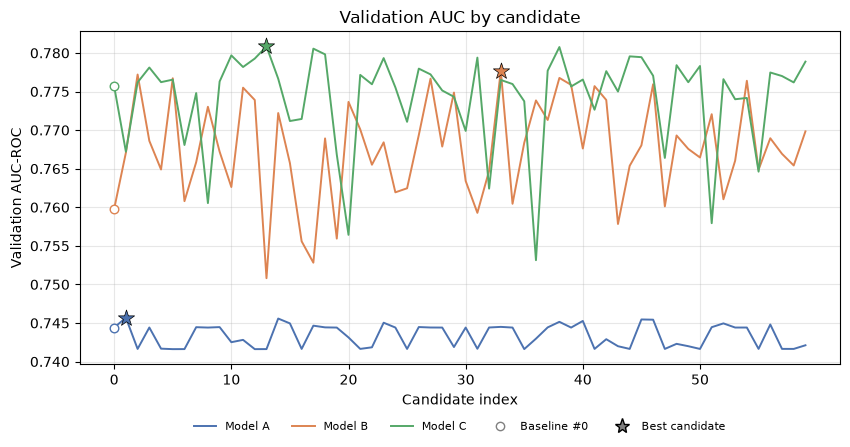

In [12]:
# 11. Validation AUC by candidate.
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(8.6, 4.6))
colors = {"A": "#4C72B0", "B": "#DD8452", "C": "#55A868"}
all_trials = {"A": trials_a, "B": trials_b, "C": trials_c}

for name in ("A", "B", "C"):
    trials = all_trials[name]
    color = colors[name]
    ax.plot(trials["candidate"], trials["AUC"], color=color, linewidth=1.4, label=f"Model {name}")
    baseline_auc = trials.loc[trials["candidate"] == 0, "AUC"].iloc[0]
    ax.scatter(0, baseline_auc, facecolor="white", edgecolor=color, s=38, zorder=4)
    best_row = best[name]
    ax.scatter(best_row["candidate"], best_row["AUC"], marker="*", s=150,
               color=color, edgecolor="black", linewidth=0.5, zorder=5)

handles = [Line2D([0], [0], color=colors[name], linewidth=1.4, label=f"Model {name}")
           for name in ("A", "B", "C")]
handles.append(Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                      markeredgecolor="grey", markersize=6, label="Baseline #0"))
handles.append(Line2D([0], [0], marker="*", color="none", markerfacecolor="grey",
                      markeredgecolor="black", markersize=11, label="Best candidate"))

ax.set_xlabel("Candidate index")
ax.set_ylabel("Validation AUC-ROC")
ax.set_title("Validation AUC by candidate")
ax.set_xticks(range(0, N_CANDIDATES, 10))
ax.grid(alpha=0.3)
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.14),
          ncol=5, frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_6_1_candidate_auc.png", dpi=300)
plt.show()

In [13]:
# 12. Save candidate tables and best configurations.
for name, trials in all_trials.items():
    trials.to_csv(MODEL_DIR / f"trials_{name}.csv", index=False)

best_configs = {}
for name in ("A", "B", "C"):
    row = best[name]
    best_configs[name] = {
        "model": MODEL_NAMES[name],
        "candidate": int(row["candidate"]),
        "params": {param: clean_param(param, row[param]) for param in SPACES[name]},
        "metrics": {metric: float(row[metric]) for metric in
                    ("Accuracy", "Precision", "Recall", "F1", "AUC", "PR-AUC")},
        "fit_time_seconds": float(row["Fit time (s)"]),
    }
(MODEL_DIR / "best_configs.json").write_text(
    json.dumps(best_configs, indent=2), encoding="utf-8")
print("Saved trials_A/B/C.csv and best_configs.json")

Saved trials_A/B/C.csv and best_configs.json


In [14]:
# 13. Save the three Chapter 6 tables.
def fmt(value):
    if value is None:
        return "None"
    if isinstance(value, float):
        return f"{value:g}"
    return str(value)

space_rows = []
for name in ("A", "B", "C"):
    for param, values in SPACES[name].items():
        if isinstance(values, dict):
            display_values = f"{values['low']:g} to {values['high']:g} (log-uniform)"
        else:
            display_values = ", ".join(fmt(v) for v in values)
        space_rows.append({
            "Model": name,
            "Parameter": param,
            "Values": display_values,
            "Baseline": fmt(BASELINE[name][param]),
        })
table_06_01 = pd.DataFrame(space_rows)
table_06_01.to_csv(OUT_DIR / "table06_01_search_spaces.csv", index=False)

best_rows = []
for name in ("A", "B", "C"):
    row = best[name]
    for param in SPACES[name]:
        best_rows.append({
            "Model": name,
            "Best candidate": int(row["candidate"]),
            "Parameter": param,
            "Value": fmt(clean_param(param, row[param])),
            "AUC": round(float(row["AUC"]), 4),
            "PR-AUC": round(float(row["PR-AUC"]), 4),
            "F1": round(float(row["F1"]), 4),
        })
table_06_02 = pd.DataFrame(best_rows)
table_06_02.to_csv(OUT_DIR / "table06_02_best_configs.csv", index=False)

table_06_03 = before_after.round(4)
table_06_03.to_csv(OUT_DIR / "table06_03_before_after.csv", index=False)

print("Saved table06_01_search_spaces.csv")
print("Saved table06_02_best_configs.csv")
print("Saved table06_03_before_after.csv")

Saved table06_01_search_spaces.csv
Saved table06_02_best_configs.csv
Saved table06_03_before_after.csv


## Rank-weighted cross-entropy

The tuned Model C is used to test a ranking-aware extension of the class-weighted loss. AUC is a pairwise statistic, so a natural idea is to give more weight to positives that are ranked below many negatives and to negatives that are ranked above many positives. The weight of a positive is the share of negatives that outrank it, and the weight of a negative is the share of positives that it outranks. The weights are normalised within each class and the original positive class weight is applied, so the comparison isolates the ranking reweighting. The main experiment is the two-sided form, RW1. The positive-only form, RW0, and the capped form, RW2, are kept as ablations. The comparison uses seed 42, the same seed as the tuning run.


In [15]:
# 15. Rank-weighted cross-entropy: setup and objective.
C_BEST = {param: clean_param(param, best["C"][param]) for param in SPACES["C"]}
RANK_SEEDS = [42]
RANK_ROUNDS = int(C_BEST["n_estimators"])

rank_dtrain = xgboost.DMatrix(train[FEATURES], label=train[TARGET])
rank_dval = xgboost.DMatrix(val[FEATURES], label=val[TARGET])
rank_y = train[TARGET].to_numpy()
rank_pos = np.flatnonzero(rank_y == 1)
rank_neg = np.flatnonzero(rank_y == 0)

def rank_weights(scores, mode="two_sided"):
    w = np.ones_like(scores)
    neg_sorted = np.sort(scores[rank_neg])
    above = len(rank_neg) - np.searchsorted(neg_sorted, scores[rank_pos], side="left")
    r = above / len(rank_neg)
    w[rank_pos] = r / max(r.mean(), 1e-12)
    if mode == "two_sided":
        pos_sorted = np.sort(scores[rank_pos])
        below = np.searchsorted(pos_sorted, scores[rank_neg], side="right")
        s = below / len(rank_pos)
        w[rank_neg] = s / max(s.mean(), 1e-12)
    return w

def make_rank_objective(mode="two_sided", cap=None, floor=None, fixed_w=None):
    def objective(preds, dmat):
        y = dmat.get_label()
        p = 1.0 / (1.0 + np.exp(-preds))
        if fixed_w is None:
            w = rank_weights(preds, mode=mode)
            if cap is not None:
                w = np.minimum(w, cap)
                w[rank_pos] = w[rank_pos] / max(w[rank_pos].mean(), 1e-12)
                w[rank_neg] = w[rank_neg] / max(w[rank_neg].mean(), 1e-12)
            if floor is not None:
                w = floor + (1.0 - floor) * w
        else:
            w = fixed_w
        g = w * (p - y)
        h = w * p * (1.0 - p)
        g[rank_pos] *= C_BEST["scale_pos_weight"]
        h[rank_pos] *= C_BEST["scale_pos_weight"]
        return g, np.maximum(h, 1e-6)
    return objective

def rank_params(seed, weighted=False):
    return {
        "tree_method": "hist",
        "max_depth": int(C_BEST["max_depth"]),
        "eta": float(C_BEST["learning_rate"]),
        "subsample": float(C_BEST["subsample"]),
        "colsample_bytree": float(C_BEST["colsample_bytree"]),
        "min_child_weight": float(C_BEST["min_child_weight"]),
        "gamma": float(C_BEST["gamma"]),
        "lambda": float(C_BEST["reg_lambda"]),
        "nthread": -1,
        "seed": seed,
        "objective": "binary:logistic",
        "base_score": 0.5,
        "scale_pos_weight": float(C_BEST["scale_pos_weight"]) if weighted else 1,
    }


In [16]:
# 16. Rank-weighted fits: C0, RW0, RW1 and RW2 at seed 42.
RANK_VARIANTS = [
    ("C0", "class-weighted log-loss", None),
    ("RW0", "positive-only rank weighting", ("one_sided", None, None)),
    ("RW1", "two-sided rank weighting", ("two_sided", None, None)),
    ("RW2", "two-sided, cap 3", ("two_sided", 3.0, None)),
]
rank_rows = []
rank_seed42 = {}
for seed in RANK_SEEDS:
    for name, description, spec in RANK_VARIANTS:
        if spec is None:
            booster = xgboost.train(rank_params(seed, weighted=True), rank_dtrain,
                                    num_boost_round=RANK_ROUNDS, verbose_eval=False)
        else:
            mode, cap, floor = spec
            booster = xgboost.train(rank_params(seed), rank_dtrain,
                                    num_boost_round=RANK_ROUNDS,
                                    obj=make_rank_objective(mode=mode, cap=cap, floor=floor),
                                    verbose_eval=False)
        p_val = booster.predict(rank_dval)
        p_train = booster.predict(rank_dtrain)
        rank_rows.append({
            "Variant": name,
            "Description": description,
            "seed": seed,
            "AUC": roc_auc_score(val[TARGET], p_val),
            "PR-AUC": average_precision_score(val[TARGET], p_val),
            "Train AUC": roc_auc_score(train[TARGET], p_train),
            "Val AUC": roc_auc_score(val[TARGET], p_val),
        })
        if seed == 42:
            rank_seed42[name] = {"booster": booster, "train_pred": p_train, "val_pred": p_val}
        print(f"{name} seed {seed}: train {rank_rows[-1]['Train AUC']:.4f}  val {rank_rows[-1]['Val AUC']:.4f}")
rank_results = pd.DataFrame(rank_rows)


C0 seed 42: train 0.8464  val 0.7808


RW0 seed 42: train 0.9237  val 0.7579


RW1 seed 42: train 0.9838  val 0.6763


RW2 seed 42: train 0.9934  val 0.6797


In [17]:
# 17. Rank-weighted summary table at seed 42.
rank_table = rank_results[["Variant", "Description", "AUC", "PR-AUC", "Train AUC", "Val AUC"]].copy()
rank_table["Delta AUC"] = rank_table["AUC"] - rank_table.loc[rank_table["Variant"] == "C0", "AUC"].iloc[0]
rank_table = rank_table[["Variant", "Description", "AUC", "Delta AUC", "PR-AUC", "Train AUC", "Val AUC"]]
display(rank_table.round(4))


,Variant,Description,AUC,Delta AUC,PR-AUC,Train AUC,Val AUC
0,C0,class-weighted log-loss,0.7808,0.0000,0.5553,0.8464,0.7808
1,RW0,positive-only rank weighting,0.7579,-0.0229,0.4964,0.9237,0.7579
2,RW1,two-sided rank weighting,0.6763,-0.1046,0.3795,0.9838,0.6763
3,RW2,"two-sided, cap 3",0.6797,-0.1011,0.3962,0.9934,0.6797


In [18]:
# 18. Diagnostics: fixed weights, a uniform-weight check and a weight floor.
c0 = rank_seed42["C0"]
z0 = np.log(np.clip(c0["train_pred"], 1e-9, 1.0 - 1e-9) /
            (1.0 - np.clip(c0["train_pred"], 1e-9, 1.0 - 1e-9)))
w_static = rank_weights(z0, mode="two_sided")

uniform_booster = xgboost.train(rank_params(42), rank_dtrain, num_boost_round=RANK_ROUNDS,
                                obj=make_rank_objective(fixed_w=np.ones(len(rank_y))),
                                verbose_eval=False)
uniform_train = uniform_booster.predict(rank_dtrain)
uniform_val = uniform_booster.predict(rank_dval)

static_booster = xgboost.train(rank_params(42), rank_dtrain, num_boost_round=RANK_ROUNDS,
                               obj=make_rank_objective(fixed_w=w_static), verbose_eval=False)
static_train = static_booster.predict(rank_dtrain)
static_val = static_booster.predict(rank_dval)

floor_booster = xgboost.train(rank_params(42), rank_dtrain, num_boost_round=RANK_ROUNDS,
                              obj=make_rank_objective(mode="two_sided", floor=0.7), verbose_eval=False)
floor_train = floor_booster.predict(rank_dtrain)
floor_val = floor_booster.predict(rank_dval)

diagnostics = pd.DataFrame([
    {"Variant": "C0", "Train AUC": roc_auc_score(train[TARGET], c0["train_pred"]),
     "Val AUC": roc_auc_score(val[TARGET], c0["val_pred"])},
    {"Variant": "Uniform-weight custom", "Train AUC": roc_auc_score(train[TARGET], uniform_train),
     "Val AUC": roc_auc_score(val[TARGET], uniform_val)},
    {"Variant": "Static weights", "Train AUC": roc_auc_score(train[TARGET], static_train),
     "Val AUC": roc_auc_score(val[TARGET], static_val)},
    {"Variant": "Dynamic floor 0.7", "Train AUC": roc_auc_score(train[TARGET], floor_train),
     "Val AUC": roc_auc_score(val[TARGET], floor_val)},
])
display(diagnostics.round(4))


,Variant,Train AUC,Val AUC
0,C0,0.8464,0.7808
1,Uniform-weight custom,0.8464,0.7808
2,Static weights,0.2539,0.2252
3,Dynamic floor 0.7,0.9129,0.7694


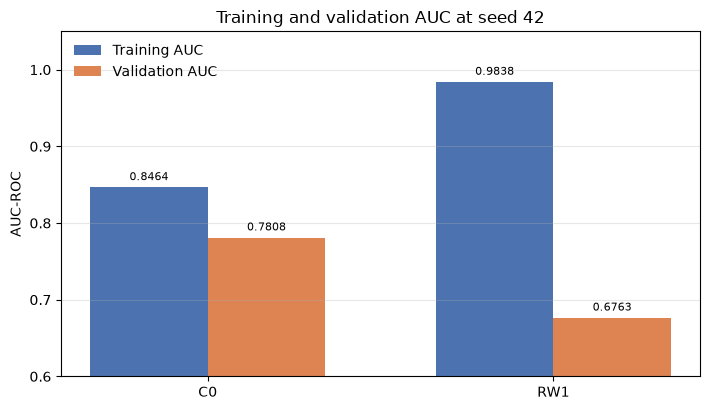

Saved table06_04_rank_weighted.csv
Saved table06_05_rank_weighted_diagnostics.csv
Saved fig_6_2_rank_weighted.png


In [19]:
# 19. Save the rank-weighted table and figure.
rank_table.to_csv(OUT_DIR / "table06_04_rank_weighted.csv", index=False)
rank_results.to_csv(MODEL_DIR / "ch06_rank_weighted_results.csv", index=False)
diagnostics.to_csv(OUT_DIR / "table06_05_rank_weighted_diagnostics.csv", index=False)

plot_table = rank_table[rank_table["Variant"].isin(["C0", "RW1"])].copy()
labels = plot_table["Variant"].tolist()
x = np.arange(len(labels))
width = 0.34
train_values = plot_table["Train AUC"].to_numpy()
val_values = plot_table["Val AUC"].to_numpy()
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.bar(x - width / 2, train_values, width, label="Training AUC", color="#4C72B0")
ax.bar(x + width / 2, val_values, width, label="Validation AUC", color="#DD8452")
for xi, value in zip(x - width / 2, train_values):
    ax.text(xi, value + 0.006, f"{value:.4f}", ha="center", va="bottom", fontsize=8)
for xi, value in zip(x + width / 2, val_values):
    ax.text(xi, value + 0.006, f"{value:.4f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, labels)
ax.set_ylim(0.60, 1.05)
ax.set_ylabel("AUC-ROC")
ax.set_title("Training and validation AUC at seed 42")
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_6_2_rank_weighted.png", dpi=300)
plt.show()
print("Saved table06_04_rank_weighted.csv")
print("Saved table06_05_rank_weighted_diagnostics.csv")
print("Saved fig_6_2_rank_weighted.png")


In [20]:
# 20. Save tuned validation probabilities and the run manifest.
tuned_predictions = pd.DataFrame({
    ID_COL: val[ID_COL],
    TARGET: val[TARGET],
    "p_A": probabilities_a[int(best["A"]["candidate"])],
    "p_B": probabilities_b[int(best["B"]["candidate"])],
    "p_C": probabilities_c[int(best["C"]["candidate"])],
})
tuned_predictions.to_csv(PRED_DIR / "ch06_tuned_val.csv", index=False)

manifest = {
    "chapter": "06_hyperparameter_optimisation",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "random_seed": SEED,
    "notebook": "bank/notebook/06_Hyperparameter_Optimisation.ipynb",
    "data": {
        "train_rows": int(len(train)),
        "validation_rows": int(len(val)),
        "features": int(len(FEATURES)),
        "train_positive_rate": float(train[TARGET].mean()),
        "validation_positive_rate": float(val[TARGET].mean()),
        "test_split_used": False,
    },
    "protocol": {
        "split": "stratified_70_15_15",
        "cross_validation": False,
        "candidates_per_model": N_CANDIDATES,
        "baseline_candidate_index": 0,
        "selection_metric": "roc_auc",
        "tie_breakers": ["pr_auc", "f1_at_0.5", "candidate_index"],
    },
    "rank_weighted": {
        "seeds": RANK_SEEDS,
        "boosting_rounds": RANK_ROUNDS,
        "variants": ["C0", "RW0", "RW1", "RW2"],
        "diagnostics": ["uniform-weight custom", "static weights", "dynamic floor 0.7"],
    },
    "models": {},
    "environment": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "matplotlib": matplotlib.__version__,
    },
    "artifacts": {
        "trials_A": "bank/data_processed/model_results/trials_A.csv",
        "trials_B": "bank/data_processed/model_results/trials_B.csv",
        "trials_C": "bank/data_processed/model_results/trials_C.csv",
        "best_configs": "bank/data_processed/model_results/best_configs.json",
        "tuned_validation_probabilities": "bank/data_processed/predictions/ch06_tuned_val.csv",
        "rank_weighted_results": "bank/data_processed/model_results/ch06_rank_weighted_results.csv",
        "table_06_01": "bank/outputs/chapter_06/table06_01_search_spaces.csv",
        "table_06_02": "bank/outputs/chapter_06/table06_02_best_configs.csv",
        "table_06_03": "bank/outputs/chapter_06/table06_03_before_after.csv",
        "table_06_04": "bank/outputs/chapter_06/table06_04_rank_weighted.csv",
        "table_06_05": "bank/outputs/chapter_06/table06_05_rank_weighted_diagnostics.csv",
        "figure_06_01": "bank/outputs/chapter_06/fig_6_1_candidate_auc.png",
        "figure_06_02": "bank/outputs/chapter_06/fig_6_2_rank_weighted.png",
    },
    "runtime_seconds": {
        "A": float(trials_a["Fit time (s)"].sum()),
        "B": float(trials_b["Fit time (s)"].sum()),
        "C": float(trials_c["Fit time (s)"].sum()),
    },
}
for name in ("A", "B", "C"):
    row = best[name]
    manifest["models"][name] = {
        "estimator": {"A": "LogisticRegression",
                      "B": "RandomForestClassifier",
                      "C": "XGBClassifier"}[name],
        "library": "xgboost" if name == "C" else "scikit-learn",
        "version": xgboost.__version__ if name == "C" else sklearn.__version__,
        "best_candidate": int(row["candidate"]),
        "best_params": {param: clean_param(param, row[param]) for param in SPACES[name]},
        "best_metrics": {metric: float(row[metric]) for metric in
                         ("Accuracy", "Precision", "Recall", "F1", "AUC", "PR-AUC")},
    }
(OUT_DIR / "run_manifest.json").write_text(
    json.dumps(manifest, indent=2), encoding="utf-8")
print("Saved ch06_tuned_val.csv and run_manifest.json")


Saved ch06_tuned_val.csv and run_manifest.json
